# 01 — CICIDS-2017 Exploratory Data Analysis & Preprocessing Audit
Executes `clean_cicids.py` and `build_splits.py` and visualizes row sanitization, feature pruning (`|r| > 0.98`), class imbalance, and chronological splits.

In [1]:
import sys
import json
from pathlib import Path

ML_SERVICE_ROOT = Path.cwd().resolve()
if ML_SERVICE_ROOT.name == "notebooks":
    ML_SERVICE_ROOT = ML_SERVICE_ROOT.parent
if str(ML_SERVICE_ROOT) not in sys.path:
    sys.path.insert(0, str(ML_SERVICE_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
from src.config import settings
from src.logger import setup_logging

setup_logging()
print("Connected to ML Service Root:", ML_SERVICE_ROOT)
from src.preprocessing.clean_cicids import run_cleaning
from src.preprocessing.build_splits import build_chronological_splits

Connected to ML Service Root: C:\Users\Dell\Desktop\ea-idrs\ml-service


In [2]:
clean_parquet = settings.PROCESSED_DIR / "cicids2017_clean.parquet"
audit_json = settings.PROCESSED_DIR / "preprocessing_audit.json"

if not clean_parquet.exists() or not audit_json.exists():
    run_cleaning()
if not (settings.SPLITS_DIR / "split_metadata.json").exists():
    build_chronological_splits()

with open(audit_json, encoding="utf-8") as f:
    audit = json.load(f)
with open(settings.SPLITS_DIR / "split_metadata.json", encoding="utf-8") as f:
    split_meta = json.load(f)

df = pd.read_parquet(clean_parquet, engine="pyarrow")
print(f"Loaded cleaned dataset: {df.shape[0]:,} rows x {df.shape[1]} columns")

Loaded cleaned dataset: 2,827,876 rows x 51 columns


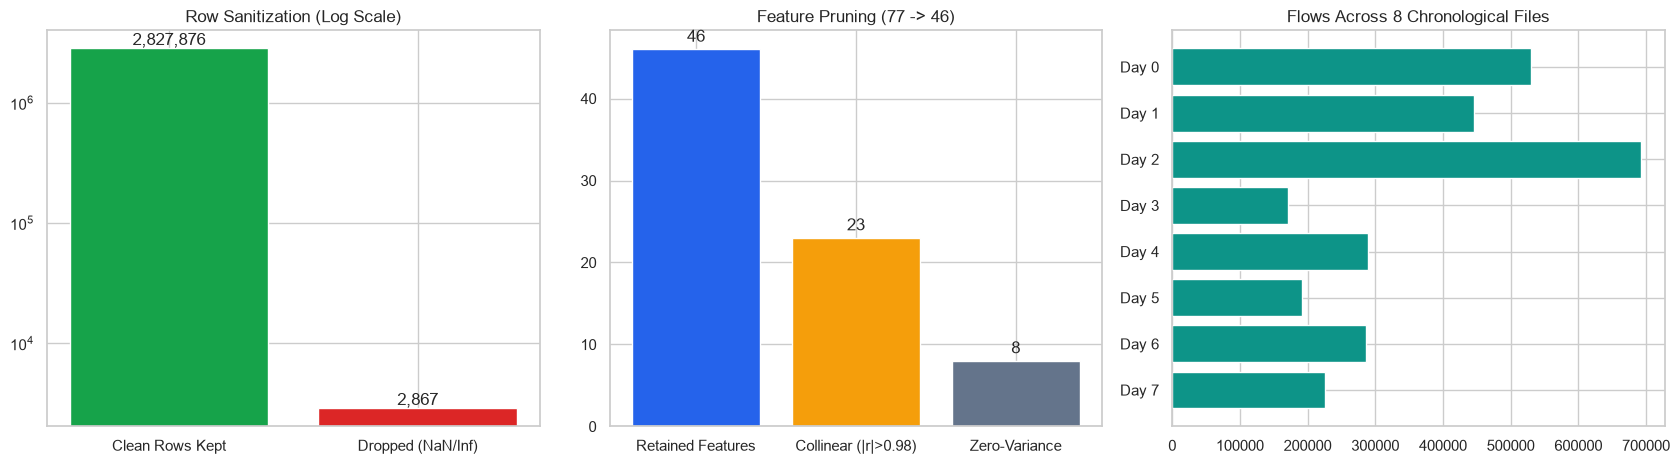

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

row_labels = ["Clean Rows Kept", "Dropped (NaN/Inf)"]
row_vals = [audit["clean_total_rows"], audit["dropped_nan_inf_rows"]]
bars0 = axes[0].bar(row_labels, row_vals, color=["#16a34a", "#dc2626"])
axes[0].set_yscale("log")
axes[0].set_title("Row Sanitization (Log Scale)")
for b in bars0:
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height(), f"{int(b.get_height()):,}", ha="center", va="bottom")

feat_labels = ["Retained Features", "Collinear (|r|>0.98)", "Zero-Variance"]
feat_vals = [audit["final_feature_count"], len(audit["collinear_dropped"]), len(audit["zero_variance_dropped"])]
bars1 = axes[1].bar(feat_labels, feat_vals, color=["#2563eb", "#f59e0b", "#64748b"])
axes[1].set_title(f"Feature Pruning ({audit['initial_feature_count']} -> {audit['final_feature_count']})")
for b in bars1:
    axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.5, f"{int(b.get_height())}", ha="center", va="bottom")

short_names = [f"Day {i}" for i in range(len(audit["file_row_counts"]))]
axes[2].barh(short_names[::-1], list(audit["file_row_counts"].values())[::-1], color="#0d9488")
axes[2].set_title("Flows Across 8 Chronological Files")
plt.tight_layout()
plt.show()

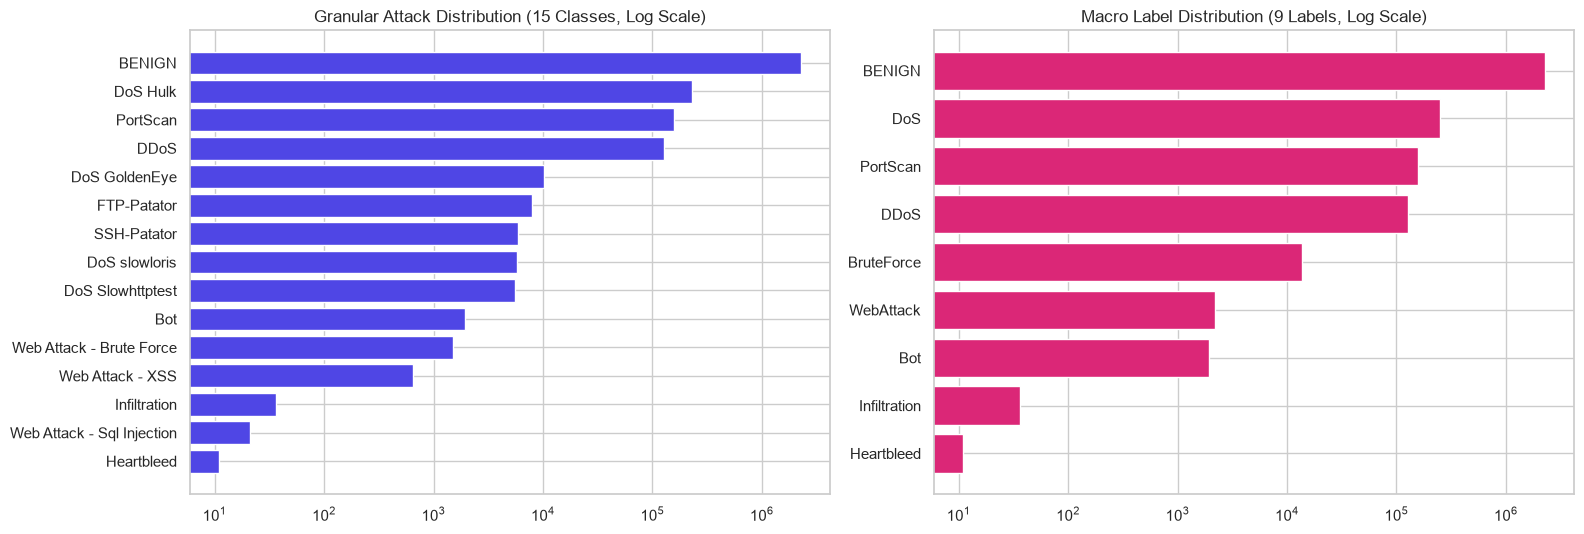

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
gran = pd.Series(audit["granular_class_counts"]).sort_values(ascending=True)
axes[0].barh(gran.index, gran.values, color="#4f46e5")
axes[0].set_xscale("log")
axes[0].set_title("Granular Attack Distribution (15 Classes, Log Scale)")

macro = pd.Series(audit["macro_class_counts"]).sort_values(ascending=True)
axes[1].barh(macro.index, macro.values, color="#db2777")
axes[1].set_xscale("log")
axes[1].set_title(f"Macro Label Distribution ({len(macro)} Labels, Log Scale)")
# build_splits drops labels with < 50 flows (Infiltration, Heartbleed), so the model uses the rest.
plt.tight_layout()
plt.show()

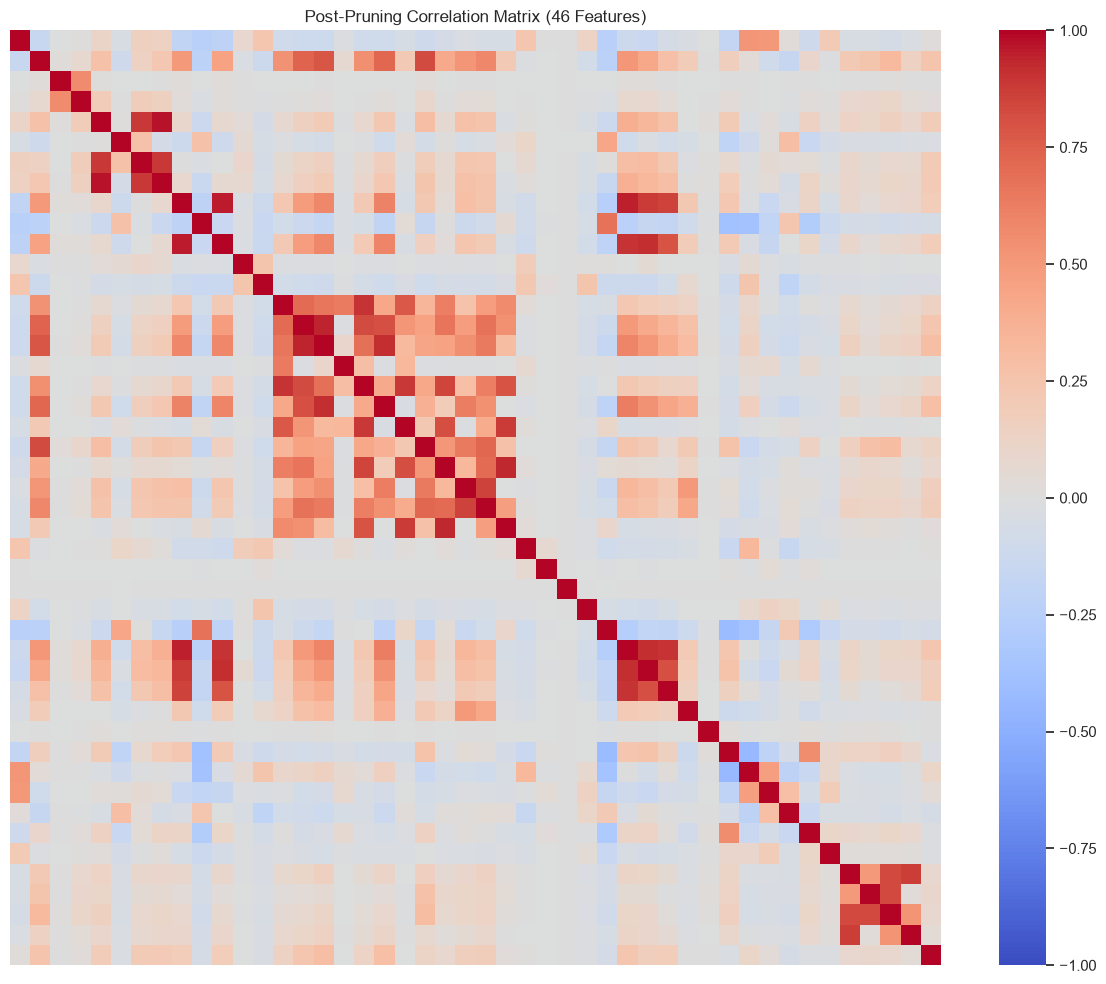

In [5]:
feature_cols = split_meta["feature_cols"]
corr = df[feature_cols].sample(n=50_000, random_state=settings.RANDOM_SEED).corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, xticklabels=False, yticklabels=False)
plt.title(f"Post-Pruning Correlation Matrix ({len(feature_cols)} Features)")
plt.tight_layout()
plt.show()